In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
geo = 'GSE175435'
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', geo)
pth_out = os.path.join(pth_data, 'cancer', 'invertebrate', 'drosophila')
pth_res = os.path.join(pth_data, 'results', 'cancer', 'drosophila')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'invertebrate', 'drosophila')

In [3]:
adata = sc.read_loom(os.path.join(pth_in, 'GSM5333520_LglIR.loom'))
adata

AnnData object with n_obs × n_vars = 19313 × 13948
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

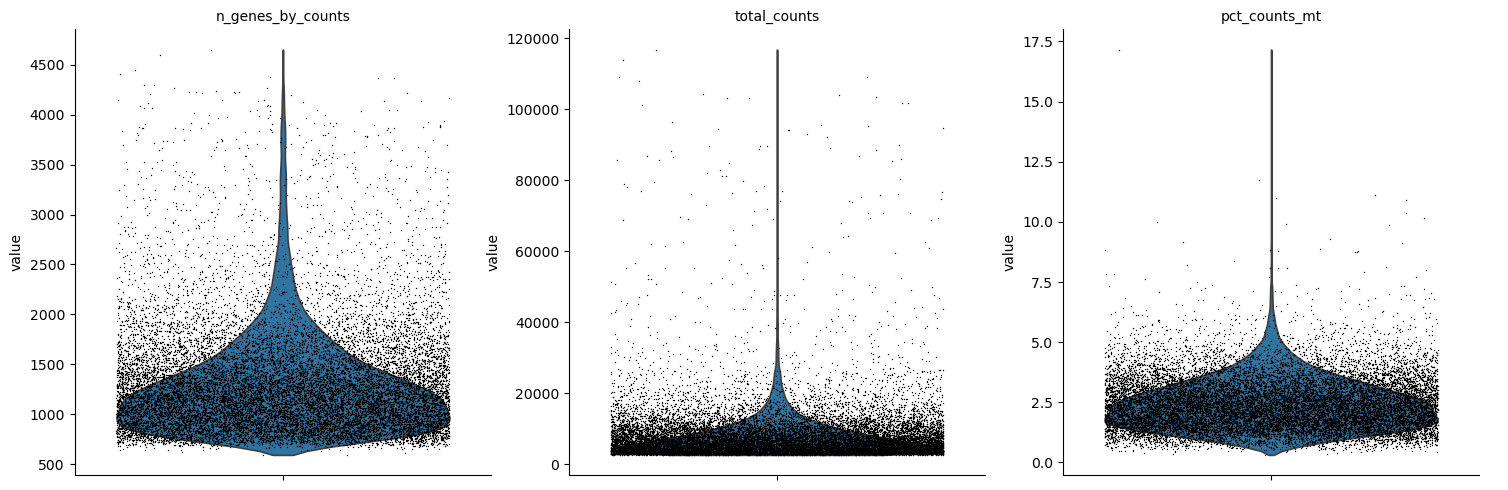

In [4]:
adata.var['mt'] = adata.var_names.str.startswith('mt:')
sc.pp.calculate_qc_metrics(adata, qc_vars = ['mt'],
                           percent_top = None,
                           inplace = True,
                           log1p = False)
sc.pl.violin(adata, ['n_genes_by_counts',
                     'total_counts',
                     'pct_counts_mt'],
             jitter = .4, multi_panel = True)

In [5]:
sc.pp.filter_cells(adata, min_genes = 600)
sc.pp.filter_cells(adata, max_genes = 1800)
sc.pp.filter_cells(adata, max_counts = 15000)
adata = adata[adata.obs.pct_counts_mt < 4.5].copy()
adata

AnnData object with n_obs × n_vars = 16063 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [6]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [7]:
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)
sc.pp.pca(adata, mask_var = 'highly_variable')
sc.pp.neighbors(adata, n_neighbors = 100)
sc.tl.leiden(adata, flavor = 'igraph')

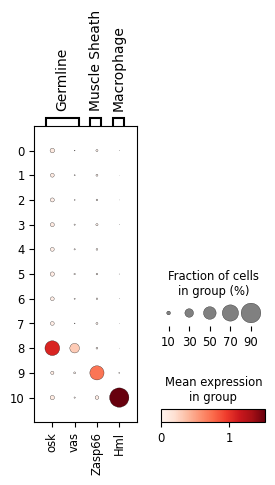

In [8]:
genes = {'Germline'        : ['osk', 'vas'],
         'Muscle Sheath'   : ['Zasp66'],
         'Macrophage'      : ['Hml']}
sc.pl.dotplot(adata, genes, 'leiden')

In [9]:
remove = ['8', '9', '10']
adata = adata[~adata.obs.leiden.isin(remove)].copy()
adata

AnnData object with n_obs × n_vars = 15039 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [10]:
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)
sc.pp.pca(adata, mask_var = 'highly_variable')
sc.pp.neighbors(adata, n_neighbors = 100)
sc.tl.leiden(adata, flavor = 'igraph', resolution = 1.2)

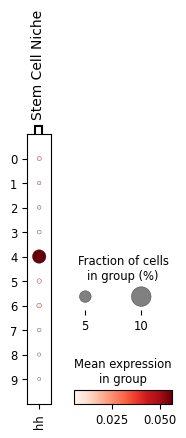

In [11]:
sc.pl.dotplot(adata, {'Stem Cell Niche' : ['hh']}, 'leiden')

In [12]:
adata = adata[adata.obs.leiden != '4'].copy()
adata

AnnData object with n_obs × n_vars = 13540 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [13]:
sc.tl.leiden(adata, flavor = 'igraph', resolution = 1.5)

In [14]:
sc.pp.neighbors(adata)
sc.tl.diffmap(adata, n_comps = 30)

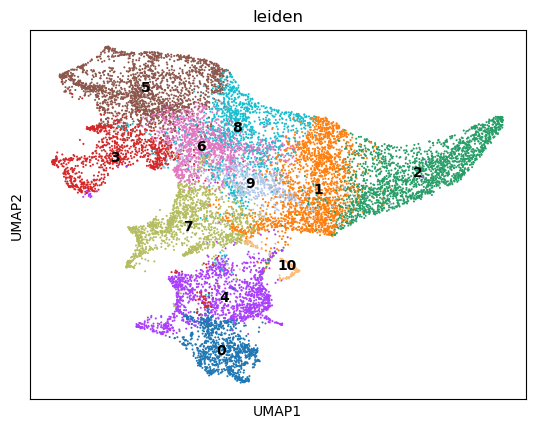

In [15]:
sc.pp.neighbors(adata, n_neighbors = 200, use_rep = 'X_diffmap')
sc.tl.umap(adata, spread = 2)
sc.pl.umap(adata, color = 'leiden', legend_loc = 'on data')

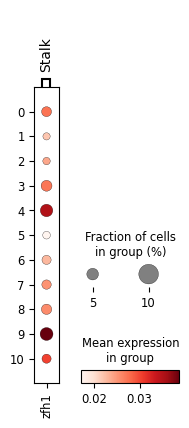

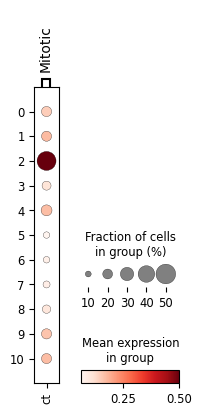

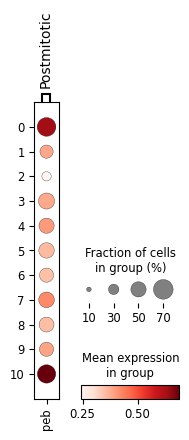

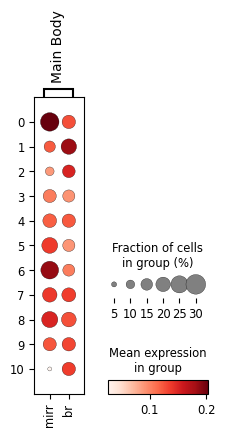

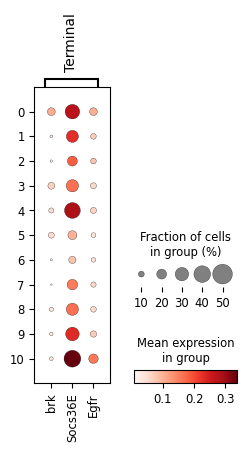

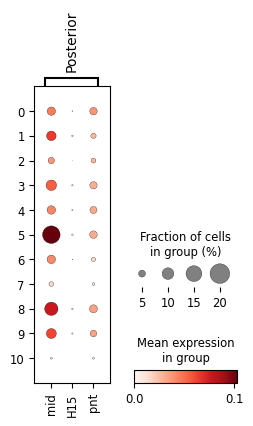

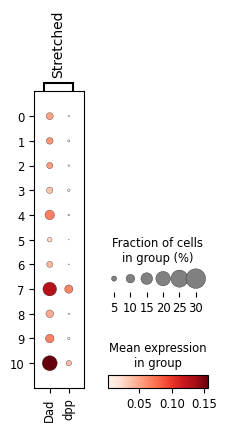

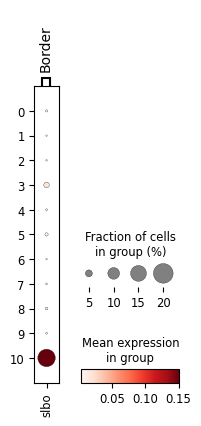

In [16]:
genes = {
    'Stalk'       : ['zfh1'],
    'Mitotic'     : ['ct'],
    'Postmitotic' : ['peb'],
    'Main Body'   : ['mirr', 'br'],
    'Terminal'    : ['brk', 'Socs36E', 'Egfr'],
    'Posterior'   : ['mid', 'H15', 'pnt'],
    'Stretched'   : ['Dad', 'dpp'],
    'Border'      : ['slbo']}

for key, val in genes.items():
    sc.pl.dotplot(adata, {key : val}, 'leiden')

In [17]:
adata = adata[adata.obs.leiden != '10'].copy()
adata

AnnData object with n_obs × n_vars = 13429 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'diffmap_evals', 'umap', 'leiden_colors'
    obsm: 'X_pca', 'X_diffmap', 'X_umap'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [18]:
celltype_dict = {
    '0'  : 'Main Body',
    '1'  : 'Postmitotic',
    '2'  : 'Mitotic',
    '3'  : 'Border',
    '4'  : 'Terminal',
    '5'  : 'Posterior',
    '6'  : 'Postmitotic',
    '7'  : 'Stretched',
    '8'  : 'Postmitotic',
    '9'  : 'Stalk'}

adata.obs['celltype'] = adata.obs.leiden.map(celltype_dict).astype('category')

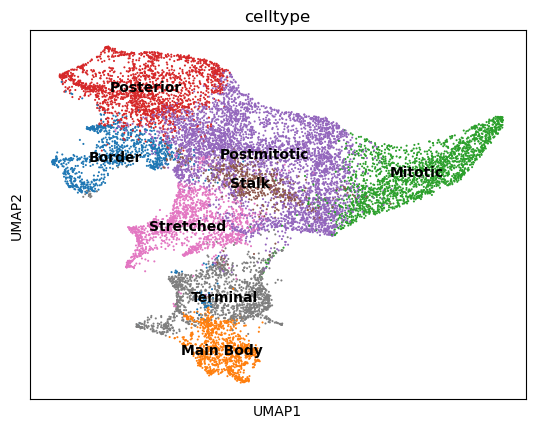

In [19]:
sc.pl.umap(adata, color = 'celltype', legend_loc = 'on data')

In [20]:
adata.write(os.path.join(pth_out, 'follicle.h5ad'))

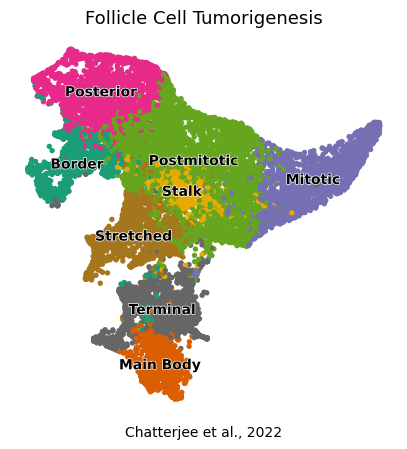

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'celltype', size = 60,
           palette = 'Dark2', legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.set_title('Follicle Cell Tumorigenesis', size = 13)
ax.text(.5, -.05, 'Chatterjee et al., 2022',
        ha = 'center', transform = ax.transAxes)
fn = os.path.join(pth_fig, 'processed.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [10]:
df = adata.obs.celltype.value_counts(sort = False)
df.to_csv(os.path.join(pth_res, 'processed.csv'))